In [1]:
import matplotlib.pyplot as plt
import numpy as np
from Bio import Align
from Bio.SeqUtils import seq1
from prody import *

g1_ca = parsePDB("8wflout.pdb").select("protein and calpha")
g2_ca = parsePDB("9hueout.pdb").select("protein and calpha")
g1_model_ca = parsePDB("remodelled_glyt1_bestout.pdb").select(
    "protein and calpha"
)

seq_g1 = "".join([seq1(res) for res in g1_ca.getResnames()])
seq_g2 = "".join([seq1(res) for res in g2_ca.getResnames()])
seq_g1_model = "".join([seq1(res) for res in g1_model_ca.getResnames()])

aligner = Align.PairwiseAligner()
aligner.mode = "global"
aligner.substitution_matrix = Align.substitution_matrices.load("BLOSUM62")
aligner.open_gap_score = -10
aligner.extend_gap_score = -0.5

aln = aligner.align(seq_g1, seq_g2)[0]
aligned_g1, aligned_g2 = aln[0], aln[1]

g1_indices = []
g2_indices = []
idx_g1 = 0
idx_g2 = 0

for a, b in zip(aligned_g1, aligned_g2):
  if a != "-" and b != "-":
    g1_indices.append(idx_g1)
    g2_indices.append(idx_g2)
  if a != "-":
    idx_g1 += 1
  if b != "-":
    idx_g2 += 1

if seq_g1 == seq_g1_model:
  g1_model_indices = g1_indices
else:
  aln_mod = aligner.align(seq_g1, seq_g1_model)[0]
  g1_to_mod = {}
  i_g1, i_mod = 0, 0
  for a, m in zip(aln_mod[0], aln_mod[1]):
    if a != "-" and m != "-":
      g1_to_mod[i_g1] = i_mod
    if a != "-":
      i_g1 += 1
    if m != "-":
      i_mod += 1

  # Retain only indices present in all three
  valid_triplets = [i for i in g1_indices if i in g1_to_mod]
  g2_indices = [
      g2_indices[k] for k, i in enumerate(g1_indices) if i in g1_to_mod
  ]
  g1_model_indices = [g1_to_mod[i] for i in valid_triplets]
  g1_indices = valid_triplets

matched_g1 = g1_ca[g1_indices]
matched_g2 = g2_ca[g2_indices]
matched_g1_model = g1_model_ca[g1_model_indices]

cutoff = 13.0
n_modes = 15  

anm1 = ANM("GlyT1")
anm1.buildHessian(matched_g1, cutoff=cutoff)
anm1.calcModes(n_modes=n_modes)
dccm1 = calcCrossCorr(anm1)

anm2 = ANM("GlyT2")
anm2.buildHessian(matched_g2, cutoff=cutoff)
anm2.calcModes(n_modes=n_modes)
dccm2 = calcCrossCorr(anm2)

delta_dccm_exp = dccm1 - dccm2  # Experimental divergence

def merge_selections(sel1, sel2, title="Complex"):
  if sel1 is None or sel2 is None:
    raise ValueError(
        f"Cannot merge selections for '{title}': one of the selections is None.\n"
        f"  sel1: {type(sel1)} | sel2: {type(sel2)}"
    )

  combined = AtomGroup(title)
  coords = np.vstack([sel1.getCoords(), sel2.getCoords()])
  resnums = list(sel1.getResnums()) + list(sel2.getResnums())
  resnames = list(sel1.getResnames()) + list(sel2.getResnames())
  names = list(sel1.getNames()) + list(sel2.getNames())

  elems1 = list(sel1.getElements()) if sel1.getElements() is not None else []
  elems2 = list(sel2.getElements()) if sel2.getElements() is not None else []
  elements = (
      elems1 + elems2
      if (len(elems1) == len(sel1) and len(elems2) == len(sel2))
      else None
  )

  combined.setCoords(coords)
  combined.setResnums(resnums)
  combined.setResnames(resnames)
  combined.setNames(names)
  if elements is not None:
    combined.setElements(elements)

  return combined

# Re-parse the ligands directly
lig_sele_g1 = parsePDB("8wflout.pdb").select("resname W5X and not hydrogen")
lig_sele_g2 = parsePDB("9hueout.pdb").select("resname A1E and not hydrogen")

# Merge matched CA subsets with their respective ligands
complex_g1 = merge_selections(matched_g1, lig_sele_g1, "GlyT1_W5X")
complex_g2 = merge_selections(matched_g2, lig_sele_g2, "GlyT2_A1E")

@> 4414 atoms and 1 coordinate set(s) were parsed in 0.02s.
@> 4697 atoms and 1 coordinate set(s) were parsed in 0.02s.
@> 5145 atoms and 1 coordinate set(s) were parsed in 0.02s.
@> Hessian was built in 0.07s.
@> 15 modes were calculated in 0.23s.
@> Hessian was built in 0.10s.
@> 15 modes were calculated in 0.22s.
@> 4414 atoms and 1 coordinate set(s) were parsed in 0.02s.
@> 4697 atoms and 1 coordinate set(s) were parsed in 0.02s.


In [2]:
cutoff = 13.0
n_modes = 15
n_prot = len(matched_g1)

# Holo ANMs
anm1_holo = ANM("GlyT1_Holo")
anm1_holo.buildHessian(complex_g1, cutoff=cutoff)
anm1_holo.calcModes(n_modes=n_modes)

anm2_holo = ANM("GlyT2_Holo")
anm2_holo.buildHessian(complex_g2, cutoff=cutoff)
anm2_holo.calcModes(n_modes=n_modes)

# Extract Protein CA RMSFs (Holo: first n_prot nodes)
rmsf1_apo = np.sqrt(calcSqFlucts(anm1))
rmsf1_holo = np.sqrt(calcSqFlucts(anm1_holo)[:n_prot])
delta_rmsf_g1 = rmsf1_apo - rmsf1_holo  # Positive = rigidified by W5X

rmsf2_apo = np.sqrt(calcSqFlucts(anm2))
rmsf2_holo = np.sqrt(calcSqFlucts(anm2_holo)[:n_prot])
delta_rmsf_g2 = rmsf2_apo - rmsf2_holo  # Positive = rigidified by A1E

# Extract Protein CA DCCMs and difference
dccm1_holo_prot = calcCrossCorr(anm1_holo)[:n_prot, :n_prot]
delta_dccm_g1 = dccm1_holo_prot - dccm1 

dccm2_holo_prot = calcCrossCorr(anm2_holo)[:n_prot, :n_prot]
delta_dccm_g2 = dccm2_holo_prot - dccm2

@> Hessian was built in 0.10s.
@> 15 modes were calculated in 0.23s.
@> Hessian was built in 0.10s.
@> 15 modes were calculated in 0.25s.


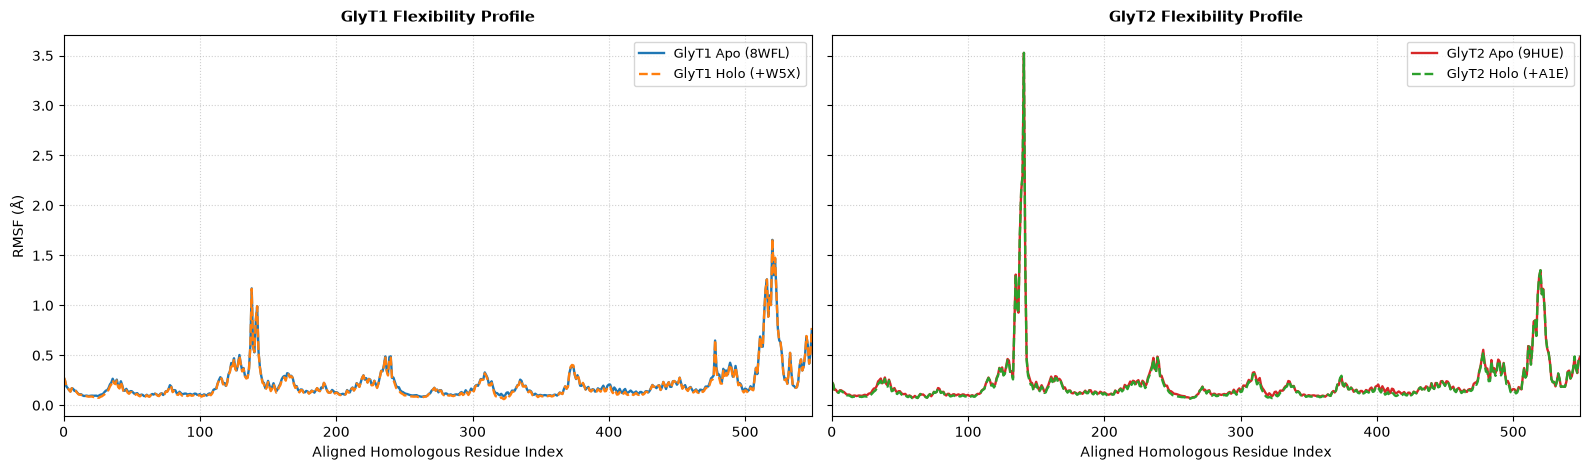

In [ ]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 4.8), sharey=True)

# Panel 1: GlyT1 (Apo vs. Holo [W5X])
ax1.plot(
    rmsf1_apo,
    label="GlyT1 Apo (8WFL)",
    color="#1f77b4",
    linewidth=1.7,
)
ax1.plot(
    rmsf1_holo,
    label="GlyT1 Holo (+W5X)",
    color="#ff7f0e",
    linestyle="--",
    linewidth=1.7,
)

ax1.set_title("GlyT1 Flexibility Profile", fontweight="bold", fontsize=11, pad=10)
ax1.set_xlabel("Aligned Homologous Residue Index", fontsize=10)
ax1.set_ylabel(r"RMSF ($\mathrm{\AA}$)", fontsize=10)
ax1.set_xlim(0, n_prot - 1)
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(frameon=True, loc="upper right", fontsize=9)


# Panel 2: GlyT2 (Apo vs. Holo [A1E])
ax2.plot(
    rmsf2_apo,
    label="GlyT2 Apo (9HUE)",
    color="#d62728",
    linewidth=1.7,
)
ax2.plot(
    rmsf2_holo,
    label="GlyT2 Holo (+A1E)",
    color="#2ca02c",
    linestyle="--",
    linewidth=1.7,
)

ax2.set_title("GlyT2 Flexibility Profile", fontweight="bold", fontsize=11, pad=10)
ax2.set_xlabel("Aligned Homologous Residue Index", fontsize=10)
ax2.set_xlim(0, n_prot - 1)
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(frameon=True, loc="upper right", fontsize=9)


plt.tight_layout()
plt.show()

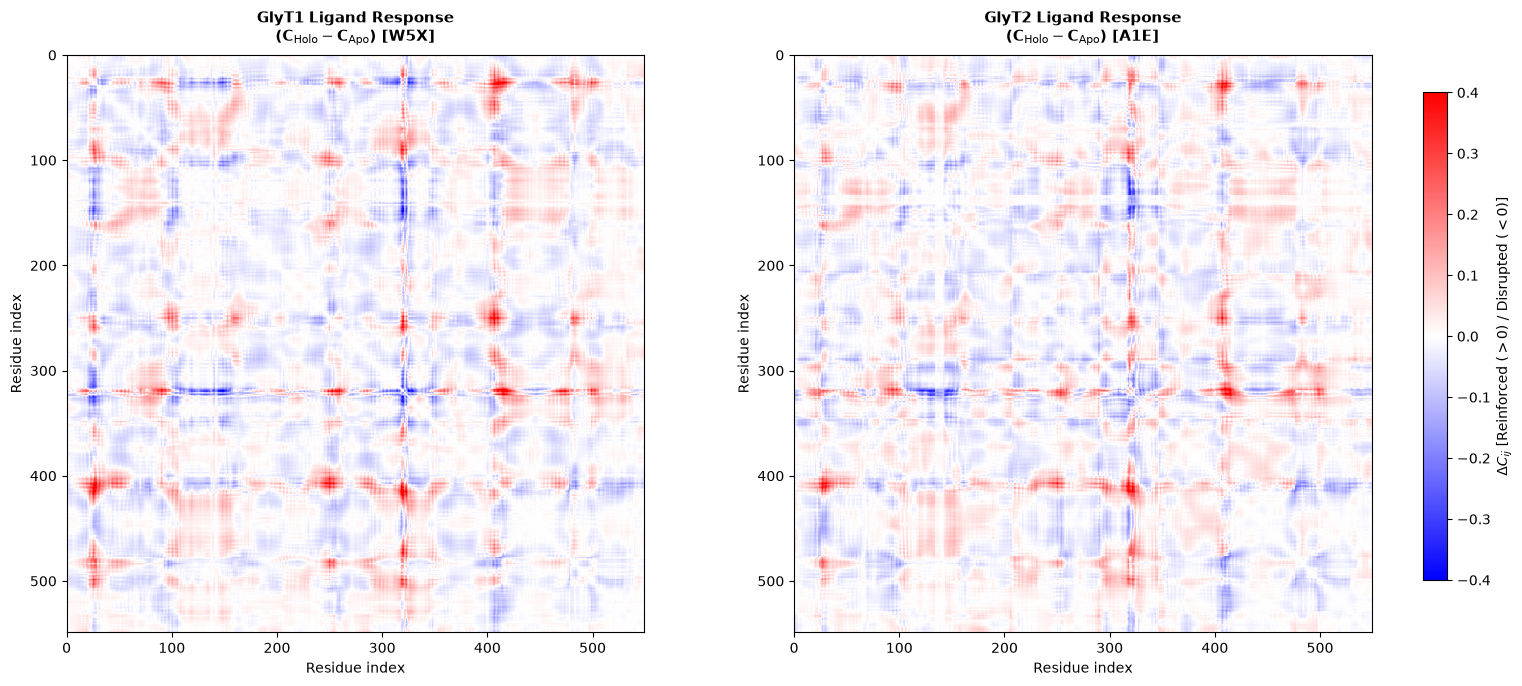

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7.5))
vlim = 0.4  # Binding-induced shifts typically sit within +/- 0.35

for ax, mat, title, lig_name in zip(
    [ax1, ax2],
    [delta_dccm_g1, delta_dccm_g2],
    ["GlyT1 Ligand Response", "GlyT2 Ligand Response"],
    ["W5X", "A1E"],
):
  im = ax.imshow(
      mat,
      cmap="bwr",
      vmin=-vlim,
      vmax=vlim,
      origin="upper",
      interpolation="nearest",
  )
  ax.set_xlim(0, n_prot - 1)
  ax.set_ylim(n_prot - 1, 0)

  ax.set_title(
      f"{title}\n" + r"($\mathbf{C}_{\mathrm{Holo}} - \mathbf{C}_{\mathrm{Apo}}$)"
      + f" [{lig_name}]",
      fontsize=11,
      fontweight="bold",
      pad=10,
  )
  ax.set_xlabel("Residue index", fontsize=10)
  ax.set_ylabel("Residue index", fontsize=10)

# Shared Colorbar
cbar_ax = fig.add_axes([0.92, 0.18, 0.015, 0.65])
cbar = fig.colorbar(im, cax=cbar_ax)
cbar.set_label(
    r"$\Delta C_{ij}$ [Reinforced ($>0$) / Disrupted ($<0$)]", fontsize=10
)

plt.subplots_adjust(left=0.06, right=0.90, wspace=0.18)
plt.show()

In [35]:
raw_overlap = calcOverlap(anm_mod_clean[0], anm1_clean[0])
sign = 1.0 if raw_overlap > 0 else -1.0

# Generate trajectory oscillating along the rocking bundle mode
ensemble_mod = traverseMode(sign * anm_mod_clean[0], matched_mod_sup, n_steps=20, rmsd=1.5)
writePDB("model_mode01_traj.pdb", ensemble_mod)

print(f"Raw overlap with GlyT1 M1: {raw_overlap:.3f} (applied sign correction: {sign})")

@> Parameter: rmsd = 1.50 A
@> Parameter: n_steps = 20
@> Step size is 0.08 A RMSD
@> Mode is scaled by 1.7589106003495456.


Raw overlap with GlyT1 M1: -0.971 (applied sign correction: -1.0)


In [36]:
# Mode eigenvalues (stiffness along the rocking coordinate)
eig_g1 = anm1_clean[0].getEigval()        # Mode 1
eig_g2 = anm2_clean[1].getEigval()        # Mode 2
eig_mod = anm_mod_clean[0].getEigval()    # Mode 1

print(f"GlyT1 (8WFL) Mode 1 Stiffness (eigenvalue): {eig_g1:.4e}")
print(f"GlyT2 (9HUE) Mode 2 Stiffness (eigenvalue): {eig_g2:.4e}")
print(f"Model        Mode 1 Stiffness (eigenvalue): {eig_mod:.4e}")

GlyT1 (8WFL) Mode 1 Stiffness (eigenvalue): 8.4916e-02
GlyT2 (9HUE) Mode 2 Stiffness (eigenvalue): 1.0978e-01
Model        Mode 1 Stiffness (eigenvalue): 1.0656e-01
